In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("iris.txt")

In [3]:
print(df.head())

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa


In [4]:
X = df.drop(columns=["species"])
X = StandardScaler().fit_transform(X)


In [5]:

wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)


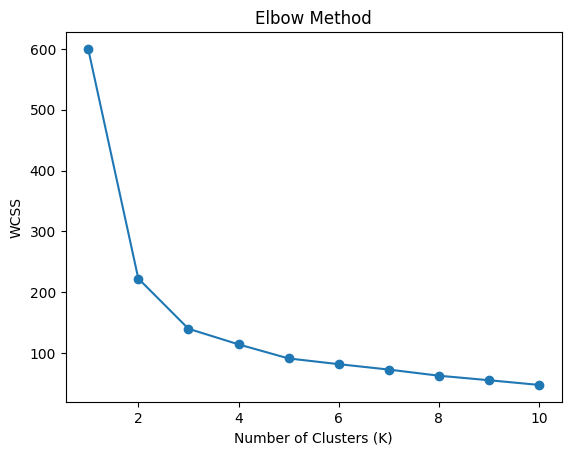

In [6]:

plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


In [7]:

km = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = km.fit_predict(X)


In [8]:

print("Optimal clusters selected: 3")
print(df[["species", "Cluster"]].head())

print("\nCluster counts:\n", df["Cluster"].value_counts())


Optimal clusters selected: 3
  species  Cluster
0  setosa        1
1  setosa        1
2  setosa        1
3  setosa        1
4  setosa        1

Cluster counts:
 Cluster
0    53
1    50
2    47
Name: count, dtype: int64
